# Importação dos Dados

In [2]:
!pip install ucimlrepo --quiet

from ucimlrepo import fetch_ucirepo
import pandas as pd

maternal_health_risk = fetch_ucirepo(id=863)

X = maternal_health_risk.data.features
y = maternal_health_risk.data.targets

df = pd.concat([X, y], axis=1)
df.head()

,Age,SystolicBP,DiastolicBP,BS,BodyTemp,HeartRate,RiskLevel
0,25,130,80,15.0,98.0,86,high risk
1,35,140,90,13.0,98.0,70,high risk
2,29,90,70,8.0,100.0,80,high risk
3,30,140,85,7.0,98.0,70,high risk
4,35,120,60,6.1,98.0,76,low risk


# Estatísticas Descritivas

In [3]:
df.info()
df.describe()
df['RiskLevel'].value_counts()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1014 entries, 0 to 1013
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Age          1014 non-null   int64  
 1   SystolicBP   1014 non-null   int64  
 2   DiastolicBP  1014 non-null   int64  
 3   BS           1014 non-null   float64
 4   BodyTemp     1014 non-null   float64
 5   HeartRate    1014 non-null   int64  
 6   RiskLevel    1014 non-null   object 
dtypes: float64(2), int64(4), object(1)
memory usage: 55.6+ KB


,count
RiskLevel,
low risk,406
mid risk,336
high risk,272


# Transformação de Coluna
> Codificar o alvo RiskLevel, que é categórico e ordinal (low < mid < high) em número.




In [4]:
risk_mapper = {'low risk': 0, 'mid risk': 1, 'high risk': 2}
df['RiskLevel_num'] = df['RiskLevel'].replace(risk_mapper)
df[['RiskLevel', 'RiskLevel_num']].head()

/tmp/ipykernel_4244/292208593.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['RiskLevel_num'] = df['RiskLevel'].replace(risk_mapper)


,RiskLevel,RiskLevel_num
0,high risk,2
1,high risk,2
2,high risk,2
3,high risk,2
4,low risk,0


# Transformação de Linha

> Remover as linhas duplicadas do dataset.



In [5]:
print("Duplicadas antes:", df.duplicated().sum())
df = df.drop_duplicates()
print("Linhas restantes:", df.shape[0])

Duplicadas antes: 562
Linhas restantes: 452


# Divisão em Treino, Validação e Teste

> 60% treino, 20% validação, 20% teste



In [6]:
from sklearn.model_selection import train_test_split

X = df[['Age', 'SystolicBP', 'DiastolicBP', 'BS', 'BodyTemp', 'HeartRate']]
y = df['RiskLevel_num']

X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp)

print("Treino:", X_train.shape[0])
print("Validação:", X_val.shape[0])
print("Teste:", X_test.shape[0])

Treino: 271
Validação: 90
Teste: 91


# Treinamento e Avaliação do Modelo

In [7]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

model = RandomForestClassifier(random_state=42)
model.fit(X_train, y_train)

val_pred = model.predict(X_val)
print("Acurácia na validação:", accuracy_score(y_val, val_pred))

Acurácia na validação: 0.6


# Matriz de Confusão e Acurácia

> Usar o conjunto de testes.



Acurácia no teste: 0.7142857142857143


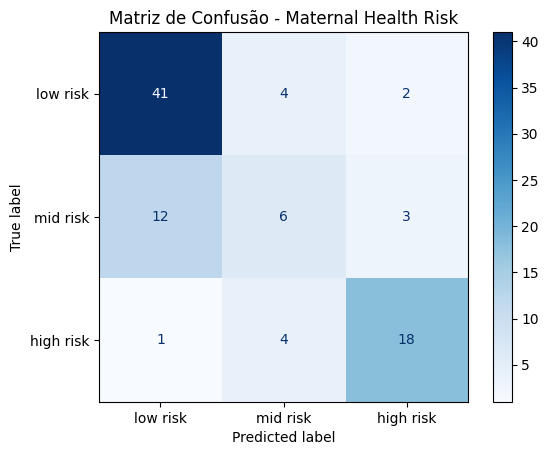

In [8]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, accuracy_score
import matplotlib.pyplot as plt

test_pred = model.predict(X_test)

acc = accuracy_score(y_test, test_pred)
print("Acurácia no teste:", acc)

cm = confusion_matrix(y_test, test_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['low risk', 'mid risk', 'high risk'])
disp.plot(cmap='Blues')
plt.title('Matriz de Confusão - Maternal Health Risk')
plt.show()

# Predição de um Exemplo

In [9]:
exemplo = pd.DataFrame({
    'Age': [32],
    'SystolicBP': [120],
    'DiastolicBP': [80],
    'BS': [7.5],
    'BodyTemp': [98.0],
    'HeartRate': [76]
})

predicao = model.predict(exemplo)
risco = {0: 'low risk', 1: 'mid risk', 2: 'high risk'}
print("Risco previsto:", risco[predicao[0]])

Risco previsto: low risk
